In [177]:
%load_ext autoreload
%autoreload 2

import platform
import sys
import hashlib
import json
import subprocess
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import itertools
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score
from time import perf_counter
from datetime import datetime, date
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from utils import (AZUL, CINZA, DIVERGENTE, FEATS, RESULTADOS, SEED, TINTA, TINTA_2, VERSAO_PREP,
                   RAIZ, HASH_TRAIN, HASH_FOLDS, carrega_dados, estilo, prepara, remove_duplicadas,
                   plota_confusao, CAT, CONT, DISC, DUMMY, CAT_NATIVAS, FrequenciaEncoder, AlvoEncoder,
                   BLOCOS, PCAColunas, DADOS, LARANJA)

pd.set_option("display.max_columns", 200)
estilo()

print(f"Python {sys.version.split()[0]} | {platform.platform()}")
for lib in (np, pd, sklearn, matplotlib):
    print(f"{lib.__name__:<12}{lib.__version__}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python 3.12.12 | macOS-26.5.1-arm64-arm-64bit
numpy       2.5.5
pandas      3.1.1
sklearn     1.9.1
matplotlib  3.11.2


In [125]:
DIR_OOF = RESULTADOS / "oof"
ARQ_RUNS = RESULTADOS / "runs.csv"
DIR_OOF.mkdir(parents=True, exist_ok=True)
RECALCULAR = False  # True força refazer tudo, ignorando o cache

def hash_config(config):
    """8 caracteres que identificam a config (com a versão da prepara)."""
    texto = json.dumps({**config, "versao_prep": VERSAO_PREP}, sort_keys=True, default=str)
    return hashlib.sha256(texto.encode()).hexdigest()[:8]


def caminho_oof(nome, h):
    return DIR_OOF / f"{nome}__{h}.csv.gz"

In [110]:
treino, teste = carrega_dados()
print("treino:", treino.shape, "| teste:", teste.shape)

treino = remove_duplicadas(treino)
print("treino sem duplicadas:", treino.shape)
print("linhas por fold:", treino["fold"].value_counts().sort_index().tolist())

treino: (47504, 129) | teste: (11877, 128)
treino sem duplicadas: (47487, 129)
linhas por fold: [9499, 9497, 9495, 9499, 9497]


In [111]:
X = prepara(treino)
y = treino["Response"].to_numpy()
fold = treino["fold"].to_numpy()
X_teste = prepara(teste)

assert list(X.columns) == list(X_teste.columns), "colunas diferentes entre treino e teste"
assert X.select_dtypes(exclude="number").empty, "sobrou coluna não numérica"
assert X["Product_Info_2"].notna().all() and X_teste["Product_Info_2"].notna().all()
assert len(X_teste) == 11_877, "o teste não pode perder linhas"

print("X:", X.shape, "| X_teste:", X_teste.shape)

X: (47487, 126) | X_teste: (11877, 126)


In [178]:
def monta_modelo(config):
    """Só o estimador final, a partir da config."""
    n_seeds = config.get("n_seeds", 1)  # ausente = 1 modelo, como nos runs antigos
    if n_seeds > 1:
        membros = [(f"s{i}", monta_modelo({**config, "n_seeds": 1, "seed": config["seed"] + i}))
                   for i in range(n_seeds)]
        return VotingClassifier(membros, voting="soft")
    nome = config["modelo"]
    params = dict(config.get("params", {}))
    cw = "balanced" if config["desbalanceamento"].startswith("balanced") else None
    if nome == "dummy":
        return DummyClassifier(random_state=config["seed"], **params)
    if nome == "rf":
        return RandomForestClassifier(class_weight=cw, random_state=config["seed"], n_jobs=-1, **params)
    if nome == "hgb":
        nativas = CAT_NATIVAS if "nativo" in config.get("encoding", "inteiro") else None
        return HistGradientBoostingClassifier(class_weight=cw, categorical_features=nativas,
                                              random_state=config["seed"], **params)
    if nome == "logistica":
        return LogisticRegression(class_weight=cw, max_iter=2000, **params)
    if nome == "extratrees":
        return ExtraTreesClassifier(class_weight=cw, random_state=config["seed"], n_jobs=-1, **params)
    if nome == "lgbm":
        return LGBMClassifier(class_weight=cw, random_state=config["seed"], n_jobs=-1, verbose=-1, **params)
    if nome == "catboost":
        cats = params.pop("cat_features", CAT)  # a config pode escolher as categóricas
        return CatBoostClassifier(auto_class_weights="Balanced" if cw else None, cat_features=cats,
                                  random_seed=config["seed"], verbose=0, **params)
    raise ValueError(f"modelo desconhecido: {nome}")


ENCODINGS = {"inteiro", "nativo", "freq_mh2", "target_mh2", "nativo+target_mh2"}


def monta_pipeline(config):
    """Pipeline completo: dados crus entram, previsão sai."""
    enc = config.get("encoding", "inteiro")    # chaves ausentes = comportamento dos runs antigos
    blocos = tuple(config.get("blocos", []))
    k_pca = config.get("pca_kw", 0)
    assert enc in ENCODINGS, f"encoding desconhecido: {enc}"
    assert set(blocos) <= set(BLOCOS), f"bloco desconhecido: {set(blocos) - set(BLOCOS)}"
    assert config["modelo"] != "logistica" or not (blocos or k_pca), "blocos e PCA ainda não valem para a logística"

    passos = [("prepara", FunctionTransformer(prepara, kw_args={"blocos": blocos}))]
    if config["modelo"] == "logistica":
        passos.append(("pre", pre_linear(config["seed"])))
    if "freq_mh2" in enc:
        passos.append(("freq", FrequenciaEncoder(["Medical_History_2"])))
    if "target_mh2" in enc:
        passos.append(("alvo", AlvoEncoder(["Medical_History_2"], seed=config["seed"])))
    if k_pca:
        passos.append(("pca_kw", PCAColunas(DUMMY, k_pca, prefixo="pca_kw", seed=config["seed"])))
    passos.append(("modelo", monta_modelo(config)))
    return Pipeline(passos)
       

In [113]:
CLASSES = np.arange(1, 9)

def avalia_cv(config, df=treino):
    """Treina e avalia a config nos 5 folds. Devolve métrica por fold, OOF e tempo."""
    y_ = df["Response"].to_numpy()
    fold_ = df["fold"].to_numpy()
    oof = np.zeros((len(df), len(CLASSES)))
    bal_acc = []
    inicio = perf_counter()

    for k in range(5):
        tr, va = fold_ != k, fold_ == k
        modelo = monta_pipeline(config).fit(df[tr], y_[tr])
        assert (modelo.classes_ == CLASSES).all()
        p = modelo.predict_proba(df[va])

        if config["desbalanceamento"].endswith("prob_freq"):
            freq = np.bincount(y_[tr], minlength=9)[1:] / tr.sum()  # frequência de cada classe no treino do fold
            p = p / freq
            p = p / p.sum(axis=1, keepdims=True)                     # volta a somar 1 em cada linha
                    
        if config["desbalanceamento"].endswith("pesos"):
            w = aprende_pesos(config, df[tr], y_[tr], fold_[tr])
            print(f"  fold {k}: pesos {np.round(w, 2)}")
            p = p * w
            p = p / p.sum(axis=1, keepdims=True)

        oof[va] = p
        bal_acc.append(balanced_accuracy_score(y_[va], CLASSES[p.argmax(axis=1)]))

    pred = CLASSES[oof.argmax(axis=1)]
    return {
        "bal_acc_folds": bal_acc,
        "oof": oof,
        "recall": recall_score(y_, pred, labels=CLASSES, average=None),
        "acc": accuracy_score(y_, pred),
        "tempo_s": perf_counter() - inicio,
    }

In [114]:
r = avalia_cv({"modelo": "dummy", "params": {"strategy": "most_frequent"},
               "desbalanceamento": "nada", "seed": SEED})
print("balanced accuracy por fold:", np.round(r["bal_acc_folds"], 4))
print("recall por classe:", np.round(r["recall"], 2))
print(f"acurácia: {r['acc']:.3f} | tempo: {r['tempo_s']:.1f}s")

balanced accuracy por fold: [0.125 0.125 0.125 0.125 0.125]
recall por classe: [0. 0. 0. 0. 0. 0. 0. 1.]
acurácia: 0.329 | tempo: 0.1s


In [115]:
def roda(nome, experimento, config):
    """Avalia a config nos 5 folds, ou lê do cache se essa mesma config já rodou. Devolve a linha do runs.csv."""
    h = hash_config(config)
    runs = pd.read_csv(ARQ_RUNS) if ARQ_RUNS.exists() else pd.DataFrame(columns=["run", "config_hash"])
    no_cache = (runs["run"] == nome) & (runs["config_hash"] == h)

    if no_cache.any() and caminho_oof(nome, h).exists() and not RECALCULAR:
        print(f"{nome}: lido do cache")
        return runs[no_cache].iloc[-1]

    r = avalia_cv(config)
    linha = {
        "run": nome, "config_hash": h, "experimento": experimento,
        "data_hora": datetime.now().isoformat(timespec="seconds"),
        "config": json.dumps(config, sort_keys=True, default=str),
        **{f"bal_acc_f{k}": v for k, v in enumerate(r["bal_acc_folds"])},
        "bal_acc_media": np.mean(r["bal_acc_folds"]),
        "bal_acc_desvio": np.std(r["bal_acc_folds"], ddof=1),
        "acc": r["acc"],
        **{f"recall_c{c}": v for c, v in zip(CLASSES, r["recall"])},
        "tempo_s": r["tempo_s"],
        "data_hash": HASH_TRAIN, "folds_hash": HASH_FOLDS, "versao_prep": VERSAO_PREP,
    }

    oof = pd.DataFrame(r["oof"].round(4), columns=[f"p{c}" for c in CLASSES])
    oof.insert(0, "Id", treino["Id"].to_numpy())
    oof.to_csv(caminho_oof(nome, h), index=False)
    runs = runs[~no_cache]  # recalculou: substitui a linha antiga em vez de duplicar
    pd.concat([runs, pd.DataFrame([linha])], ignore_index=True).to_csv(ARQ_RUNS, index=False)

    print(f"{nome}: {r['tempo_s']:.0f}s | balanced accuracy {linha['bal_acc_media']:.4f}")
    return pd.Series(linha)


def carrega_oof(linha):
    """Probabilidades OOF de um run, na mesma ordem de linhas do treino."""
    oof = pd.read_csv(caminho_oof(linha["run"], linha["config_hash"]))
    assert (oof["Id"].to_numpy() == treino["Id"].to_numpy()).all(), "OOF fora da ordem do treino"
    return oof[[f"p{c}" for c in CLASSES]].to_numpy()

In [116]:
LIMIAR = 0.005


def compara(linhas, controle=None):
    """Tabela dos runs. Com controle: ganho pareado, folds com ganho e se passa na regra de decisão."""
    tab = pd.DataFrame(linhas).set_index("run")
    cols_folds = [f"bal_acc_f{k}" for k in range(5)]
    cols = ["bal_acc_media", "bal_acc_desvio", "acc"] + [f"recall_c{c}" for c in CLASSES] + ["tempo_s"]
    saida = tab[cols].astype(float)
    if controle is not None:
        dif = tab[cols_folds].astype(float).sub(tab.loc[controle, cols_folds].astype(float), axis=1)
        saida.insert(2, "ganho", dif.mean(axis=1))
        saida.insert(3, "folds com ganho", (dif > 0).sum(axis=1))
        saida.insert(4, "passa", (saida["ganho"] >= LIMIAR) & (saida["folds com ganho"] >= 4))
    return saida.round(4)

In [117]:
dummy = {"modelo": "dummy", "params": {"strategy": "most_frequent"}, "desbalanceamento": "nada", "seed": SEED}

linha = roda("E00-r01-dummy-mais_frequente", "E00", dummy)  # 1ª vez: avalia e grava
linha = roda("E00-r01-dummy-mais_frequente", "E00", dummy)  # 2ª vez: tem que ler do cache
compara([linha])

E00-r01-dummy-mais_frequente: 0s | balanced accuracy 0.1250
E00-r01-dummy-mais_frequente: 0s | balanced accuracy 0.1250


,bal_acc_media,bal_acc_desvio,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,
E00-r01-dummy-mais_frequente,0.125,0.0,0.3291,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.1001


In [118]:
RF = {"modelo": "rf", "params": {"n_estimators": 300}, "seed": SEED}

E00 = {
    "E00-r01-dummy-mais_frequente": {**dummy},
    "E00-r02-dummy-estratificado": {"modelo": "dummy", "params": {"strategy": "stratified"},
                                    "desbalanceamento": "nada", "seed": SEED},
    "E00-r03-rf-padrao": {**RF, "desbalanceamento": "nada"},
    "E00-r04-rf-balanced": {**RF, "desbalanceamento": "balanced"},
    "E00-r05-rf-balanced-seed43": {**RF, "desbalanceamento": "balanced", "seed": SEED + 1},
    "E00-r06-rf-balanced-seed44": {**RF, "desbalanceamento": "balanced", "seed": SEED + 2},
    "E00-r07-hgb-balanced": {"modelo": "hgb", "params": {}, "desbalanceamento": "balanced", "seed": SEED},
}

linhas_e00 = [roda(nome, "E00", cfg) for nome, cfg in E00.items()]
compara(linhas_e00, controle="E00-r04-rf-balanced")

E00-r01-dummy-mais_frequente: 0s | balanced accuracy 0.1250
E00-r02-dummy-estratificado: 0s | balanced accuracy 0.1232
E00-r03-rf-padrao: 18s | balanced accuracy 0.4889
E00-r04-rf-balanced: 16s | balanced accuracy 0.5134
E00-r05-rf-balanced-seed43: 16s | balanced accuracy 0.5126
E00-r06-rf-balanced-seed44: 16s | balanced accuracy 0.5124
E00-r07-hgb-balanced: 28s | balanced accuracy 0.5292


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r01-dummy-mais_frequente,0.1250,0.0000,-0.3884,0,False,0.3291,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.1020
E00-r02-dummy-estratificado,0.1232,0.0039,-0.3902,0,False,0.1919,0.0921,0.1150,0.0136,0.0253,0.0935,0.1824,0.1385,0.3252,0.1040
E00-r03-rf-padrao,0.4889,0.0075,-0.0245,0,False,0.5778,0.1749,0.2423,0.4082,0.7045,0.5237,0.5786,0.3570,0.9221,18.0440
E00-r04-rf-balanced,0.5134,0.0078,0.0000,0,False,0.5641,0.2279,0.2514,0.4876,0.7351,0.5997,0.4849,0.4873,0.8334,15.9587
E00-r05-rf-balanced-seed43,0.5126,0.0070,-0.0008,2,False,0.5647,0.2324,0.2551,0.4764,0.7343,0.5997,0.4860,0.4822,0.8347,16.1274
E00-r06-rf-balanced-seed44,0.5124,0.0077,-0.0010,2,False,0.5648,0.2271,0.2514,0.4727,0.7369,0.6044,0.4856,0.4864,0.8350,16.3372
E00-r07-hgb-balanced,0.5292,0.0095,0.0158,5,True,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773


In [119]:
tab_e00 = pd.DataFrame(linhas_e00).set_index("run")
seeds = tab_e00.loc[["E00-r04-rf-balanced", "E00-r05-rf-balanced-seed43", "E00-r06-rf-balanced-seed44"],
                    "bal_acc_media"].astype(float)

ruido = seeds.std(ddof=1)
LIMIAR = max(0.005, 2 * ruido)
print(f"balanced accuracy nas 3 seeds: {seeds.round(4).tolist()}")
print(f"desvio entre seeds: {ruido:.4f} -> LIMIAR = {LIMIAR:.4f}")

balanced accuracy nas 3 seeds: [0.5134, 0.5126, 0.5124]
desvio entre seeds: 0.0005 -> LIMIAR = 0.0050


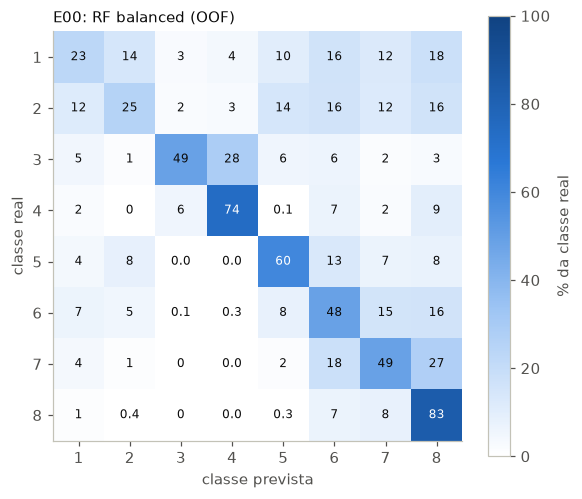

In [120]:
linha_rf = tab_e00.loc["E00-r04-rf-balanced"].copy()
linha_rf["run"] = "E00-r04-rf-balanced"  # o set_index tirou o nome da coluna; o carrega_oof precisa dele
pred_rf = CLASSES[carrega_oof(linha_rf).argmax(axis=1)]
cm_rf = plota_confusao(treino["Response"], pred_rf, "E00: RF balanced (OOF)")

In [121]:
CONTROLE = {**E00["E00-r07-hgb-balanced"]}

In [122]:
E01 = {
    "E01-r01-hgb-nada": {**CONTROLE, "desbalanceamento": "nada"},
    "E01-r02-hgb-prob_freq": {**CONTROLE, "desbalanceamento": "prob_freq"},
    "E01-r03-hgb-balanced+prob_freq": {**CONTROLE, "desbalanceamento": "balanced+prob_freq"},
}

linha_controle = linhas_e00[-1]  # o HGB balanced já avaliado no E00: não roda de novo
linhas_e01 = [linha_controle] + [roda(nome, "E01", cfg) for nome, cfg in E01.items()]
compara(linhas_e01, controle="E00-r07-hgb-balanced")

E01-r01-hgb-nada: 34s | balanced accuracy 0.4992
E01-r02-hgb-prob_freq: 36s | balanced accuracy 0.5261
E01-r03-hgb-balanced+prob_freq: 35s | balanced accuracy 0.4899


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.0000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E01-r01-hgb-nada,0.4992,0.0079,-0.0300,0,False,0.5894,0.2456,0.2554,0.4181,0.6364,0.5260,0.5382,0.4578,0.9162,34.3096
E01-r02-hgb-prob_freq,0.5261,0.0059,-0.0031,1,False,0.5664,0.2996,0.2842,0.5496,0.6600,0.5902,0.4227,0.6028,0.7997,35.8191
E01-r03-hgb-balanced+prob_freq,0.4899,0.0055,-0.0393,0,False,0.4325,0.3341,0.2827,0.6179,0.7343,0.6333,0.2254,0.6266,0.4653,34.7600


In [123]:
def otimiza_pesos(p, y_true, passos=(0.5, 0.67, 0.8, 0.9, 1.1, 1.25, 1.5, 2.0), rodadas=3):
    """Subida coordenada: ajusta o peso de uma classe por vez, fica com o que melhora a balanced accuracy."""
    w = np.ones(p.shape[1])
    melhor = balanced_accuracy_score(y_true, CLASSES[p.argmax(axis=1)])
    for _ in range(rodadas):
        for c in range(len(w)):
            for f in passos:
                w_teste = w.copy()
                w_teste[c] *= f
                ba = balanced_accuracy_score(y_true, CLASSES[(p * w_teste).argmax(axis=1)])
                if ba > melhor + 1e-6:
                    melhor, w = ba, w_teste
    return w / w.mean()


def aprende_pesos(config, df_tr, y_tr, fold_tr):
    """Pesos por classe aprendidos só com o treino do fold, via OOF interna nos folds de treino."""
    oof_interna = np.zeros((len(df_tr), len(CLASSES)))
    for j in np.unique(fold_tr):
        tr_i, va_i = fold_tr != j, fold_tr == j
        m = monta_pipeline(config).fit(df_tr[tr_i], y_tr[tr_i])
        oof_interna[va_i] = m.predict_proba(df_tr[va_i])
    return otimiza_pesos(oof_interna, y_tr)

In [124]:
linha_pesos = roda("E01-r04-hgb-balanced+pesos", "E01", {**CONTROLE, "desbalanceamento": "balanced+pesos"})
linhas_e01.append(linha_pesos)
compara(linhas_e01, controle="E00-r07-hgb-balanced")

  fold 0: pesos [1.09 0.89 1.09 0.99 0.99 0.99 0.99 0.99]
  fold 1: pesos [1.07 1.06 0.72 1.07 0.86 1.07 1.07 1.07]
  fold 2: pesos [1.   1.02 0.55 1.1  1.11 1.11 1.11 1.  ]
  fold 3: pesos [0.98 1.09 0.73 1.09 0.98 1.09 1.09 0.98]
  fold 4: pesos [0.96 0.96 0.96 0.96 0.95 0.96 1.17 1.06]
E01-r04-hgb-balanced+pesos: 155s | balanced accuracy 0.5265


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.0000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E01-r01-hgb-nada,0.4992,0.0079,-0.0300,0,False,0.5894,0.2456,0.2554,0.4181,0.6364,0.5260,0.5382,0.4578,0.9162,34.3096
E01-r02-hgb-prob_freq,0.5261,0.0059,-0.0031,1,False,0.5664,0.2996,0.2842,0.5496,0.6600,0.5902,0.4227,0.6028,0.7997,35.8191
E01-r03-hgb-balanced+prob_freq,0.4899,0.0055,-0.0393,0,False,0.4325,0.3341,0.2827,0.6179,0.7343,0.6333,0.2254,0.6266,0.4653,34.7600
E01-r04-hgb-balanced+pesos,0.5265,0.0106,-0.0027,0,False,0.5668,0.2886,0.2760,0.4950,0.7229,0.5844,0.4250,0.6220,0.7979,155.3598


In [126]:
def pre_linear(seed):
    """O que a logística precisa e as árvores não: sem NaN, escala comparável e categóricas em one-hot."""
    numericas = make_pipeline(
        SimpleImputer(strategy="median"),
        QuantileTransformer(output_distribution="normal", random_state=seed),
    )
    return ColumnTransformer([
        ("num", numericas, CONT + DISC),
        ("na", MissingIndicator(), CONT + DISC),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), CAT),
        ("kw", "passthrough", DUMMY),
    ])

In [131]:
E02 = {
    "E02-r01-logistica-balanced": {"modelo": "logistica", "params": {},
                                   "desbalanceamento": "balanced", "seed": SEED},
    "E02-r02-extratrees-balanced": {"modelo": "extratrees", "params": {"n_estimators": 300},
                                    "desbalanceamento": "balanced", "seed": SEED},
}

por_nome = {l["run"]: l for l in linhas_e00}
linhas_e02 = [por_nome["E00-r07-hgb-balanced"], por_nome["E00-r04-rf-balanced"]]
linhas_e02 += [roda(nome, "E02", cfg) for nome, cfg in E02.items()]
compara(linhas_e02, controle="E00-r07-hgb-balanced")

E02-r01-logistica-balanced: 138s | balanced accuracy 0.4528
E02-r02-extratrees-balanced: 22s | balanced accuracy 0.4179


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.0000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E00-r04-rf-balanced,0.5134,0.0078,-0.0158,0,False,0.5641,0.2279,0.2514,0.4876,0.7351,0.5997,0.4849,0.4873,0.8334,15.9587
E02-r01-logistica-balanced,0.4528,0.0083,-0.0764,0,False,0.4823,0.3127,0.2554,0.5161,0.6224,0.4513,0.2962,0.4320,0.7359,137.9523
E02-r02-extratrees-balanced,0.4179,0.0048,-0.1113,0,False,0.5402,0.2313,0.2518,0.2618,0.5201,0.3490,0.5215,0.2913,0.9162,22.1270


In [132]:
preds = {l["run"]: CLASSES[carrega_oof(l).argmax(axis=1)] for l in linhas_e02}
nomes = list(preds)
concordancia = pd.DataFrame(
    [[(preds[a] == preds[b]).mean() for b in nomes] for a in nomes], index=nomes, columns=nomes
)
concordancia.round(3)

,E00-r07-hgb-balanced,E00-r04-rf-balanced,E02-r01-logistica-balanced,E02-r02-extratrees-balanced
E00-r07-hgb-balanced,1.000,0.779,0.653,0.662
E00-r04-rf-balanced,0.779,1.000,0.629,0.758
E02-r01-logistica-balanced,0.653,0.629,1.000,0.592
E02-r02-extratrees-balanced,0.662,0.758,0.592,1.000


In [138]:
E03 = {
    "E03-r01-hgb-nativo": {**CONTROLE, "encoding": "nativo"},
    "E03-r02-hgb-freq_mh2": {**CONTROLE, "encoding": "freq_mh2"},
    "E03-r03-hgb-target_mh2": {**CONTROLE, "encoding": "target_mh2"},
}

linhas_e03 = [linha_controle] + [roda(nome, "E03", cfg) for nome, cfg in E03.items()]
compara(linhas_e03, controle="E00-r07-hgb-balanced")

E03-r01-hgb-nativo: 29s | balanced accuracy 0.5276
E03-r02-hgb-freq_mh2: 29s | balanced accuracy 0.5262


/Users/dereo/Workspace/projects/mdc/INF0619-projeto-final/final/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/dereo/Workspace/projects/mdc/INF0619-projeto-final/final/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/dereo/Workspace/projects/mdc/INF0619-projeto-final/final/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.rando

E03-r03-hgb-target_mh2: 37s | balanced accuracy 0.5247


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.0000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E03-r01-hgb-nativo,0.5276,0.0085,-0.0016,2,False,0.5666,0.2809,0.2848,0.5360,0.7072,0.5872,0.4217,0.5945,0.8082,28.7928
E03-r02-hgb-freq_mh2,0.5262,0.0100,-0.0030,1,False,0.5674,0.2819,0.2802,0.5174,0.7089,0.5902,0.4207,0.6002,0.8101,29.4118
E03-r03-hgb-target_mh2,0.5247,0.0090,-0.0045,1,False,0.5650,0.2831,0.2762,0.5186,0.7063,0.5942,0.4120,0.5991,0.8082,37.0485


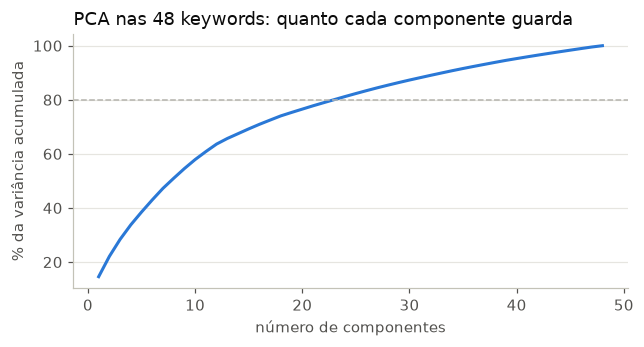

componentes para 50% / 80% / 90%: [8, 23, 34]


In [143]:
pca_ref = PCA().fit(treino[DUMMY])
acum = np.cumsum(pca_ref.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(range(1, len(acum) + 1), acum * 100, color=AZUL, linewidth=2)
ax.axhline(80, color=CINZA, linestyle="--", linewidth=1)
ax.set_xlabel("número de componentes")
ax.set_ylabel("% da variância acumulada")
ax.set_title("PCA nas 48 keywords: quanto cada componente guarda", loc="left")
plt.show()
print("componentes para 50% / 80% / 90%:", [int(np.searchsorted(acum, q) + 1) for q in (0.5, 0.8, 0.9)])

In [144]:
E05 = {
    "E05-r01-hgb-kw_soma": {**CONTROLE, "blocos": ["B"]},
    "E05-r02-hgb-pca_kw8": {**CONTROLE, "pca_kw": 8},
}

linhas_e05 = [linha_controle] + [roda(nome, "E05", cfg) for nome, cfg in E05.items()]
compara(linhas_e05, controle="E00-r07-hgb-balanced")

E05-r01-hgb-kw_soma: 28s | balanced accuracy 0.5318
E05-r02-hgb-pca_kw8: 34s | balanced accuracy 0.5279


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.0000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E05-r01-hgb-kw_soma,0.5318,0.0082,0.0026,4,False,0.5703,0.2921,0.2848,0.5385,0.7098,0.5925,0.4210,0.6059,0.8098,27.8519
E05-r02-hgb-pca_kw8,0.5279,0.0063,-0.0013,1,False,0.5681,0.2911,0.2852,0.5298,0.6993,0.5895,0.4214,0.5983,0.8083,33.9762


In [146]:
linha_e07 = roda("E07-r01-hgb-familia", "E07", {**CONTROLE, "blocos": ["E"]})
compara([linha_controle, linha_e07], controle="E00-r07-hgb-balanced")

E07-r01-hgb-familia: 27s | balanced accuracy 0.5272


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E07-r01-hgb-familia,0.5272,0.0070,-0.002,1,False,0.5676,0.2841,0.2772,0.5298,0.7045,0.5884,0.4238,0.6010,0.8091,27.4555


In [148]:
E04 = {
    "E04-r01-hgb-indicadores_na": {**CONTROLE, "blocos": ["A"]},
    "E04-r02-hgb-contagem_na": {**CONTROLE, "blocos": ["N"]},
}

linhas_e04 = [linha_controle] + [roda(nome, "E04", cfg) for nome, cfg in E04.items()]
compara(linhas_e04, controle="E00-r07-hgb-balanced")

E04-r01-hgb-indicadores_na: 33s | balanced accuracy 0.5292
E04-r02-hgb-contagem_na: 34s | balanced accuracy 0.5272


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E04-r01-hgb-indicadores_na,0.5292,0.0095,0.000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,32.5993
E04-r02-hgb-contagem_na,0.5272,0.0108,-0.002,2,False,0.5674,0.2888,0.2802,0.5285,0.7019,0.5860,0.4217,0.6028,0.8073,34.4967


In [149]:
m = monta_pipeline({**CONTROLE, "blocos": ["A"]}).fit(treino.head(2000), treino["Response"].head(2000))
print(m[-1].n_features_in_)  # esperado: 139 = 126 originais + 13 indicadores

139


In [152]:
fold_arr = treino["fold"].to_numpy()
cv_fixo = [(np.where(fold_arr != k)[0], np.where(fold_arr == k)[0]) for k in range(5)]

base = monta_pipeline({**CONTROLE, "params": {"max_iter": 600}})
espaco = {
    "modelo__learning_rate": loguniform(0.04, 0.3),
    "modelo__max_leaf_nodes": randint(15, 128),
    "modelo__min_samples_leaf": randint(10, 201),
    "modelo__l2_regularization": loguniform(1e-4, 1),
    "modelo__max_features": uniform(0.3, 0.7),  # de 0,3 a 1,0
}

busca = RandomizedSearchCV(base, espaco, n_iter=20, scoring="balanced_accuracy", cv=cv_fixo,
                           refit=False, random_state=SEED, n_jobs=1, verbose=1)
busca.fit(treino, treino["Response"])

res = pd.DataFrame(busca.cv_results_).sort_values("rank_test_score")
res.to_csv(RESULTADOS / "busca_E09.csv", index=False)
cols_param = [c for c in res.columns if c.startswith("param_")]
res[["mean_test_score", "std_test_score", "mean_fit_time"] + cols_param].head(10).round(4)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,mean_test_score,std_test_score,mean_fit_time,param_modelo__l2_regularization,param_modelo__learning_rate,param_modelo__max_features,param_modelo__max_leaf_nodes,param_modelo__min_samples_leaf
18,0.5323,0.0087,17.1032,0.1216,0.0464,0.5509,55,37
3,0.5292,0.0099,11.0838,0.2137,0.0614,0.4273,35,170
1,0.5291,0.0050,16.3722,0.0004,0.0548,0.3407,102,126
13,0.5289,0.0077,94.2364,0.0811,0.0772,0.6993,76,49
9,0.5289,0.0107,15.3313,0.0008,0.0650,0.7783,58,17
5,0.5286,0.0084,14.8051,0.0040,0.0439,0.9816,29,199
11,0.5272,0.0077,9.3685,0.0018,0.1141,0.6827,68,200
16,0.5269,0.0099,12.8276,0.0005,0.0413,0.5964,15,145
19,0.5268,0.0085,8.9405,0.2834,0.1404,0.5316,62,160
15,0.5263,0.0089,5.9616,0.7261,0.1359,0.4932,43,24


In [153]:
melhores = {k.replace("modelo__", ""): float(v) if isinstance(v, float) else int(v)
            for k, v in busca.best_params_.items()}
cfg_e09 = {**CONTROLE, "params": {"max_iter": 600, **melhores}}
print(cfg_e09)

linha_e09 = roda("E09-r01-hgb-busca", "E09", cfg_e09)
compara([linha_controle, linha_e09], controle="E00-r07-hgb-balanced")

{'modelo': 'hgb', 'params': {'max_iter': 600, 'l2_regularization': 0.12164139351417062, 'learning_rate': 0.046435871190065744, 'max_features': 0.5509260099809907, 'max_leaf_nodes': 55, 'min_samples_leaf': 37}, 'desbalanceamento': 'balanced', 'seed': 42}
E09-r01-hgb-busca: 89s | balanced accuracy 0.5323


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.0000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E09-r01-hgb-busca,0.5323,0.0097,0.0031,4,False,0.5730,0.2925,0.2816,0.5360,0.7072,0.5937,0.4366,0.5980,0.8132,89.0626


In [154]:
linha_e08 = roda("E08-r01-hgb-busca+kw_soma", "E08", {**cfg_e09, "blocos": ["B"]})
compara([linha_controle, linha_e09, linha_e08], controle="E00-r07-hgb-balanced")

E08-r01-hgb-busca+kw_soma: 76s | balanced accuracy 0.5345


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E00-r07-hgb-balanced,0.5292,0.0095,0.0000,0,False,0.5685,0.2874,0.2833,0.5335,0.7037,0.5935,0.4197,0.6044,0.8082,28.0773
E09-r01-hgb-busca,0.5323,0.0097,0.0031,4,False,0.5730,0.2925,0.2816,0.5360,0.7072,0.5937,0.4366,0.5980,0.8132,89.0626
E08-r01-hgb-busca+kw_soma,0.5345,0.0095,0.0053,5,True,0.5751,0.3011,0.2862,0.5310,0.7133,0.5949,0.4402,0.5957,0.8139,76.3073


In [155]:
CONTROLE = {**cfg_e09, "blocos": ["B"]}
linha_controle = linha_e08

In [158]:
DIR_SUB = RESULTADOS.parent / "submissoes"
DIR_SUB.mkdir(exist_ok=True)
nome = "E08-r01-hgb-busca+kw_soma"

modelo_final = monta_pipeline(CONTROLE).fit(treino, treino["Response"])
sub = pd.DataFrame({"ID": teste["ID"], "TARGET": modelo_final.predict(teste).astype(int)})

amostra = pd.read_csv(DADOS / "sample_submission.csv")
assert list(sub.columns) == list(amostra.columns)
assert len(sub) == len(amostra) and (sub["ID"].to_numpy() == amostra["ID"].to_numpy()).all()

arq = DIR_SUB / f"{date.today().isoformat()}-{nome}.csv"
sub.to_csv(arq, index=False)

dist = pd.DataFrame({
    "teste (previsto)": sub["TARGET"].value_counts(normalize=True).sort_index(),
    "treino (OOF previsto)": pd.Series(CLASSES[carrega_oof(linha_e08).argmax(axis=1)]).value_counts(normalize=True).sort_index(),
}).round(3)
print(arq.name)
dist

2026-11-24-E08-r01-hgb-busca+kw_soma.csv


,teste (previsto),treino (OOF previsto)
1,0.081,0.082
2,0.075,0.077
3,0.018,0.019
4,0.029,0.030
5,0.101,0.096
6,0.147,0.143
7,0.189,0.193
8,0.360,0.360


In [159]:
reg = DIR_SUB / "registro.csv"
nova = pd.DataFrame([{
    "data": date.today().isoformat(), "arquivo": arq.name, "run": nome,
    "config_hash": linha_e08["config_hash"], "cv_bal_acc": round(float(linha_e08["bal_acc_media"]), 4),
    "kaggle_publico": None,
}])
(pd.concat([pd.read_csv(reg), nova], ignore_index=True) if reg.exists() else nova).to_csv(reg, index=False)
pd.read_csv(reg)

,data,arquivo,run,config_hash,cv_bal_acc,kaggle_publico
0,2026-11-24,2026-11-24-E08-r01-hgb-busca+kw_soma.csv,E08-r01-hgb-busca+kw_soma,8c781e9b,0.5345,NaN


In [160]:
r = pd.read_csv(reg)
r.loc[r["arquivo"] == arq.name, "kaggle_publico"] = 0.53447
r.to_csv(reg, index=False)

In [165]:
E02b = {
    "E02b-r01-lgbm-kw_soma": {"modelo": "lgbm", "params": {}, "desbalanceamento": "balanced",
                              "seed": SEED, "blocos": ["B"]},
    "E02b-r03-catboost_leve-kw_soma": {
        "modelo": "catboost", "desbalanceamento": "balanced", "seed": SEED, "blocos": ["B"],
        "params": {"iterations": 500, "max_ctr_complexity": 1,
                    "cat_features": ["Medical_History_2", "Employment_Info_2", "Product_Info_3",
                                    "Product_Info_2", "InsuredInfo_3"]},
    },
}

linhas_e02b = [linha_controle] + [roda(nome, "E02b", cfg) for nome, cfg in E02b.items()]
compara(linhas_e02b, controle="E08-r01-hgb-busca+kw_soma")

E02b-r01-lgbm-kw_soma: lido do cache
E02b-r03-catboost_leve-kw_soma: 387s | balanced accuracy 0.5213


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E08-r01-hgb-busca+kw_soma,0.5345,0.0095,0.0000,0,False,0.5751,0.3011,0.2862,0.5310,0.7133,0.5949,0.4402,0.5957,0.8139,76.3073
E02b-r01-lgbm-kw_soma,0.5272,0.0090,-0.0073,0,False,0.5706,0.2939,0.2921,0.5074,0.7019,0.5846,0.4301,0.5976,0.8101,20.2871
E02b-r03-catboost_leve-kw_soma,0.5213,0.0091,-0.0132,0,False,0.5578,0.3202,0.2965,0.5099,0.7115,0.5879,0.4086,0.5393,0.7962,387.3013


In [169]:
arq_curva = RESULTADOS / "curva_aprendizado.csv"
fracoes = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
y_all = treino["Response"].to_numpy()
f_all = treino["fold"].to_numpy()

if arq_curva.exists() and not RECALCULAR:
    curva = pd.read_csv(arq_curva)
else:
    linhas_curva = []
    for k in range(5):
        idx_tr, idx_va = np.where(f_all != k)[0], np.where(f_all == k)[0]
        for fr in fracoes:
            if fr == 1.0:
                idx = idx_tr
            else:
                idx = train_test_split(idx_tr, train_size=fr, stratify=y_all[idx_tr], random_state=SEED)[0]
            m = monta_pipeline(CONTROLE).fit(treino.iloc[idx], y_all[idx])
            linhas_curva.append({
                "fold": k, "fração": fr, "linhas de treino": len(idx),
                "treino": balanced_accuracy_score(y_all[idx], m.predict(treino.iloc[idx])),
                "validation": balanced_accuracy_score(y_all[idx_va], m.predict(treino.iloc[idx_va])),
            })
    curva = pd.DataFrame(linhas_curva)
    curva.to_csv(arq_curva, index=False)

resumo_curva = curva.groupby("fração")[["linhas de treino", "treino", "validation"]].mean()
resumo_curva.round(4)

,linhas de treino,treino,validation
fração,,,
0.1,3798.6,1.0000,0.4593
0.2,7597.6,1.0000,0.4744
0.4,15195.6,0.7662,0.5191
0.6,22793.4,0.7360,0.5218
0.8,30391.4,0.7143,0.5313
1.0,37989.6,0.7117,0.5345


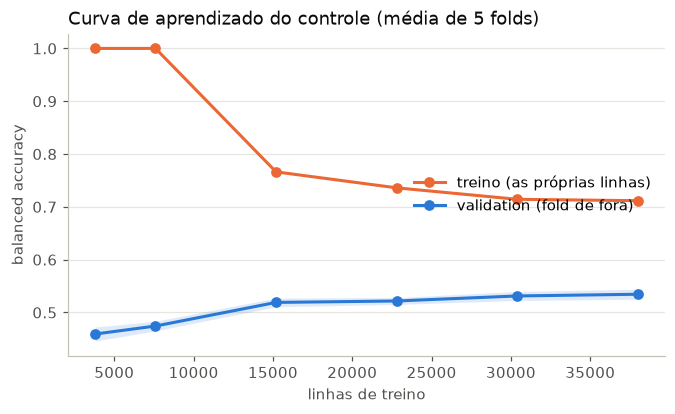

In [170]:
x = resumo_curva["linhas de treino"]
desvio_va = curva.groupby("fração")["validation"].std()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x, resumo_curva["treino"], color=LARANJA, linewidth=2, marker="o", label="treino (as próprias linhas)")
ax.plot(x, resumo_curva["validation"], color=AZUL, linewidth=2, marker="o", label="validation (fold de fora)")
ax.fill_between(x, resumo_curva["validation"] - desvio_va, resumo_curva["validation"] + desvio_va,
                color=AZUL, alpha=0.15, linewidth=0)
ax.set_xlabel("linhas de treino")
ax.set_ylabel("balanced accuracy")
ax.legend(frameon=False, loc="center right")
ax.set_title("Curva de aprendizado do controle (média de 5 folds)", loc="left")
plt.show()

In [171]:
cfg_e09b = {**CONTROLE, "params": {**CONTROLE["params"],
                                   "learning_rate": 0.02, "max_iter": 2000, "n_iter_no_change": 20}}
linha_e09b = roda("E09b-r01-hgb-lr002+kw_soma", "E09", cfg_e09b)
compara([linha_controle, linha_e09b], controle="E08-r01-hgb-busca+kw_soma")

E09b-r01-hgb-lr002+kw_soma: 160s | balanced accuracy 0.5343


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E08-r01-hgb-busca+kw_soma,0.5345,0.0095,0.0000,0,False,0.5751,0.3011,0.2862,0.5310,0.7133,0.5949,0.4402,0.5957,0.8139,76.3073
E09b-r01-hgb-lr002+kw_soma,0.5343,0.0087,-0.0002,3,False,0.5744,0.2968,0.2825,0.5372,0.7142,0.5935,0.4334,0.6005,0.8162,159.8648


In [179]:
MELHOR = cfg_e09b  # ou CONTROLE, se o E09b não passar
linha_e12 = roda("E12-r01-hgb-5seeds", "E12", {**MELHOR, "n_seeds": 5})
compara([linha_controle, linha_e12], controle="E08-r01-hgb-busca+kw_soma")

E12-r01-hgb-5seeds: 837s | balanced accuracy 0.5360


,bal_acc_media,bal_acc_desvio,ganho,folds com ganho,passa,acc,recall_c1,recall_c2,recall_c3,recall_c4,recall_c5,recall_c6,recall_c7,recall_c8,tempo_s
run,,,,,,,,,,,,,,,
E08-r01-hgb-busca+kw_soma,0.5345,0.0095,0.0000,0,False,0.5751,0.3011,0.2862,0.5310,0.7133,0.5949,0.4402,0.5957,0.8139,76.3073
E12-r01-hgb-5seeds,0.5360,0.0085,0.0015,3,False,0.5761,0.2935,0.2808,0.5385,0.7168,0.5993,0.4373,0.6050,0.8169,837.2030


In [180]:
def grade_pesos(m, passo=0.1):
    """Todas as combinações de m pesos, de passo em passo, que somam 1."""
    n = round(1 / passo)
    for c in itertools.product(range(n + 1), repeat=m):
        if sum(c) == n:
            yield np.array(c) / n


def ensemble_cv(linhas):
    """Média ponderada das OOF: pesos escolhidos em 4 folds e medidos no 5º."""
    oofs = [carrega_oof(l) for l in linhas]
    y_ = treino["Response"].to_numpy()
    f_ = treino["fold"].to_numpy()

    def nota(w, mascara):
        p = sum(wi * o[mascara] for wi, o in zip(w, oofs))
        return balanced_accuracy_score(y_[mascara], CLASSES[p.argmax(axis=1)])

    folds = []
    for k in range(5):
        tr, va = f_ != k, f_ == k
        melhor = max(grade_pesos(len(oofs)), key=lambda w: nota(w, tr))
        folds.append({"fold": k, "pesos": np.round(melhor, 1).tolist(), "bal_acc": nota(melhor, va)})
    return pd.DataFrame(folds)


por_nome = {l["run"]: l for l in linhas_e00 + linhas_e02 + linhas_e02b}
combinacoes = {
    "HGB + CatBoost": ["E08-r01-hgb-busca+kw_soma", "E02b-r03-catboost_leve-kw_soma"],
    "HGB + logística": ["E08-r01-hgb-busca+kw_soma", "E02-r01-logistica-balanced"],
    "HGB + LightGBM": ["E08-r01-hgb-busca+kw_soma", "E02b-r01-lgbm-kw_soma"],
    "HGB + CatBoost + logística": ["E08-r01-hgb-busca+kw_soma", "E02b-r03-catboost_leve-kw_soma",
                                   "E02-r01-logistica-balanced"],
    "HGB + CatBoost + logística + LightGBM": ["E08-r01-hgb-busca+kw_soma", "E02b-r03-catboost_leve-kw_soma",
                                              "E02-r01-logistica-balanced", "E02b-r01-lgbm-kw_soma"],
}

ctrl_folds = np.array([float(linha_controle[f"bal_acc_f{k}"]) for k in range(5)])
resumo_e10 = []
for nome, runs_ in combinacoes.items():
    r = ensemble_cv([por_nome[n] for n in runs_])
    dif = r["bal_acc"].to_numpy() - ctrl_folds
    resumo_e10.append({"combinação": nome, "bal_acc_media": r["bal_acc"].mean(), "ganho": dif.mean(),
                       "folds com ganho": int((dif > 0).sum()), "pesos por fold": r["pesos"].tolist()})
pd.DataFrame(resumo_e10).set_index("combinação").round(4)

,bal_acc_media,ganho,folds com ganho,pesos por fold
combinação,,,,
HGB + CatBoost,0.5331,-0.0015,0,"[[0.6, 0.4], [1.0, 0.0], [0.5, 0.5], [0.6, 0.4..."
HGB + logística,0.5332,-0.0013,1,"[[0.8, 0.2], [1.0, 0.0], [1.0, 0.0], [1.0, 0.0..."
HGB + LightGBM,0.5334,-0.0012,1,"[[1.0, 0.0], [1.0, 0.0], [0.7, 0.3], [1.0, 0.0..."
HGB + CatBoost + logística,0.5335,-0.0010,0,"[[0.6, 0.3, 0.1], [1.0, 0.0, 0.0], [0.6, 0.3, ..."
HGB + CatBoost + logística + LightGBM,0.5336,-0.0010,1,"[[0.5, 0.3, 0.1, 0.1], [0.4, 0.3, 0.0, 0.3], [..."


In [181]:
import joblib

DIR_MOD = RESULTADOS / "modelos"
DIR_MOD.mkdir(exist_ok=True)
FINAL = CONTROLE
NOME_FINAL = "E08-r01-hgb-busca+kw_soma"
assert hash_config(FINAL) == linha_controle["config_hash"], "FINAL não é a config do run registrado"

joblib.dump(modelo_final, DIR_MOD / "final.joblib")
for k in range(5):
    tr = (treino["fold"] != k).to_numpy()
    m = monta_pipeline(FINAL).fit(treino[tr], treino.loc[tr, "Response"])
    joblib.dump(m, DIR_MOD / f"fold{k}.joblib")

meta = {"run": NOME_FINAL, "config": FINAL, "config_hash": hash_config(FINAL),
        "cv_bal_acc": float(linha_controle["bal_acc_media"]), "kaggle_publico": 0.53447}
(DIR_MOD / "final.json").write_text(json.dumps(meta, indent=2, default=str))
print(sorted(p.name for p in DIR_MOD.iterdir()))

['final.joblib', 'final.json', 'fold0.joblib', 'fold1.joblib', 'fold2.joblib', 'fold3.joblib', 'fold4.joblib']


In [182]:
m0 = joblib.load(DIR_MOD / "fold0.joblib")
va = (treino["fold"] == 0).to_numpy()
dif = np.abs(m0.predict_proba(treino[va]).round(4) - carrega_oof(linha_controle)[va]).max()
print(f"maior diferença contra a OOF registrada: {dif:.4f}")  # esperado: 0,0000 ou 0,0001 (arredondamento)

maior diferença contra a OOF registrada: 0.0000


## Resumo do `02_modeling`

### Protocolo

- **Avaliação:** validação cruzada estratificada de 5 folds, fixos em `dados/folds.csv` (gerados no `01`); métrica: balanced accuracy. As 17 linhas duplicadas saem só do treino.
- **Registro:** cada run (uma configuração avaliada nos 5 folds) grava uma linha em `resultados/runs.csv` (config, hash, métrica por fold, recall por classe, tempo, versões) e as probabilidades out-of-fold (OOF) em `resultados/oof/`. Um cache por nome + hash da config evita refazer runs; um aviso dispara quando um run novo produz previsões idênticas às de outro.
- **Regra de decisão:** um run só substitui o controle se ganhar pelo menos 0,005 (o `LIMIAR`) na média e em pelo menos 4 de 5 folds, em comparação pareada fold a fold. O `LIMIAR` é o maior entre 0,005 e 2 vezes o desvio entre seeds do RF balanced (0,0005).
- **Exceção registrada (decisão 12 do plano, definida depois de ver o bloco B):** ganhos marginais e consistentes (positivos em 4 de 5 folds, abaixo do `LIMIAR`) podem ser combinados num run próprio, que precisa passar na regra normal.
- **Reprodutibilidade:** recalcular todos os runs do E00 e do E01 reproduziu os mesmos números até a 4ª casa.

### Experimentos

| Experimento | Pergunta | Resultado (CV) | Decisão |
|---|---|---|---|
| E00 | Baseline e ruído | Dummies 0,125; RF padrão 0,4889; **RF balanced 0,5134** (baseline); HGB balanced 0,5292 (+0,016, 5 de 5) | HGB balanced vira controle |
| E01 | Desbalanceamento | Sem tratamento 0,4992; prob. ÷ frequência 0,5261; correção dupla 0,4899; class weights otimizados 0,5265 | Mantém `class_weight="balanced"` |
| E02 | Famílias de modelo | Logística 0,453 (melhor recall da classe 1: 0,31); ExtraTrees 0,418 | HGB segue; logística como referência |
| E03 | Encoding das categóricas | Nativo 0,5276; frequência 0,5262; target encoding 0,5247 | Mantém o código inteiro |
| E05 | Keywords (bloco B) | Soma 0,5318 (+0,0026, 4 de 5); PCA com 8 componentes 0,5279 | Soma marginal; PCA não |
| E07 | Histórico familiar (bloco E) | 0,5272 | Não ajuda |
| E04 | Ausência (blocos A e N) | Indicadores de NA: previsões idênticas ao controle; contagens 0,5272 | Não ajuda |
| E09 | Hiperparâmetros (busca aleatória, 20 combinações) | 0,5323 (+0,0031, 4 de 5) | Marginal |
| **E08** | **Combinação dos marginais (E09 + soma de keywords)** | **0,5345 (+0,0053, 5 de 5)** | **Novo controle** |
| E09b | Taxa de aprendizado 0,02 | 0,5343 (−0,0002) | Empate |
| E02b | LightGBM e CatBoost | LightGBM 0,5272; CatBoost leve 0,5213 (padrão interrompido por tempo) | Não superam |
| E10 | Ensemble (pesos escolhidos fora do fold) | 0,5331 a 0,5336 | Não ajuda |
| E12 | Média de 5 seeds | 0,5360 (+0,0015, 3 de 5), custo 5× | Não passa |

Não realizados: E06 (o HGB corta sozinho nos extremos 0 e 240) e E11 (dois estágios para as classes 1 e 2; sem marca própria nas features, e o ensemble com os modelos de melhor recall nelas não ajudou).

### Modelo final

**HGB balanced** (`learning_rate` 0,046, 55 folhas, mínimo de 37 linhas por folha, `l2_regularization` 0,12, 55% das colunas por corte, até 600 árvores com early stopping) **com a soma de keywords.** CV 0,5345; **Kaggle 0,53447**. Recall por classe (OOF): 1: 0,30; 2: 0,29; 3: 0,53; 4: 0,71; 5: 0,59; 6: 0,44; 7: 0,60; 8: 0,81.

Salvo em `resultados/modelos/`: o modelo treinado no treino inteiro (`final.joblib`), os 5 modelos dos folds e `final.json`.

### O que aprendemos

1. **A CV prevê o teste:** 0,5345 na CV, 0,53447 no Kaggle. As decisões tomadas pela CV valem para o teste.
2. **Há um platô em ~0,535.** Encoding, features, outras famílias, ajuste fino, ensemble e média de seeds rendem no máximo +0,005. Três abordagens independentes no Kaggle (0,538, 0,536 e 0,534) param no mesmo lugar.
3. **A curva de aprendizado mostra platô suave:** a validation sobe de 0,459 (10% do treino) para 0,5345 (100%), cada vez mais devagar. No fim, o treino fica em 0,71 contra 0,53 na validation: parte do erro é ruído do alvo, uma decisão humana que depende de informação fora da base.
4. **Sinal na EDA não garante informação nova para o modelo.** Ausência, status dos pais e encoding da `Medical_History_2` tinham sinal claro na EDA, mas o HGB já o extraía sozinho (trata NaN nativamente, corta códigos inteiros). Ajudou o que a árvore não monta com facilidade: um agregado de 48 colunas (a soma de keywords).
5. **O desbalanceamento é a alavanca mais forte:** 3 pontos de diferença entre tratar e não tratar. `class_weight="balanced"` já é praticamente o ótimo: pesos otimizados por classe aprenderam ruído.
6. **Os erros seguem o que a EDA previu:** a classe 3 é absorvida pela 4, a 7 pela 8, e as classes 1 e 2 têm o pior recall, com erros espalhados.

### Limitações

- Os hiperparâmetros do modelo final foram escolhidos nos mesmos folds em que foram medidos (viés de seleção). O Kaggle confirmou o número, mas o ganho do E08 fica logo acima do `LIMIAR`.
- LightGBM e CatBoost rodaram com os parâmetros padrão (o CatBoost numa versão leve), sem o ajuste que o HGB recebeu.
- A regra para combinar ganhos marginais foi definida depois de ver o primeiro deles.

### Próximo passo

`03_analysis`: análise de erro do modelo final (classes 1, 2 e 3) e explicabilidade (permutation importance por grupo, SHAP, dependência parcial).